# BatChat vs the crowd: where Batman fans disagree

*Red Rain* is **#6** on BatChat's list, but Goodreads readers give it only **3.66/5**. *White Knight* gets a glowing **4.28/5** on Goodreads, while BatChat puts it at **#734** of 740. [Goodreads: Red Rain](https://www.goodreads.com/book/show/72479.Batman_Dracula) · [White Knight](https://www.goodreads.com/book/show/37775321-batman)

Which other books split the podcast from everyone else? And do Matt Lazorwitz and Will Nevin side more with readers or with critics?

We compare [BatChat's 740 rankings](https://comicsxf.com/batchat-rankings/) with ratings from Goodreads and Comic Book RoundUp. **Rank 1 is best; higher outside ratings are better.** Snapshot: **21 October 2026**.

*By [Dan Ofer](https://scholar.google.com/citations?user=uDx2ItYAAAAJ). New here? [Start with the Batman EDA](https://www.kaggle.com/code/danofer/who-gets-the-good-batman-stories) for writers, eras, heroes, and villains.*

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import bootstrap, spearmanr

# Kaggle mounts the dataset under /kaggle/input; locally, `make share` stages it in data/kaggle.
DATA = next(
    p.parent
    for root in ["/kaggle/input", "data/kaggle", "../data/kaggle"]
    for p in Path(root).rglob("stories.csv")
)
sns.set_theme(
    style="ticks",
    font_scale=1.05,
    rc={"axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold"},
)
BLUE, ORANGE, GREY = "#2767A0", "#D57927", "#75818C"

stories = pd.read_csv(DATA / "stories.csv")
N = len(stories)
# Flip ranks so that, like the outside ratings, higher means "more liked".
stories["preference"] = N - stories["rank"]


def spearman_interval(x, y):
    """95% bootstrap interval for the Spearman correlation of paired values."""
    result = bootstrap(
        (np.asarray(x), np.asarray(y)),
        lambda a, b: spearmanr(a, b).statistic,
        paired=True,
        vectorized=False,
        n_resamples=1000,
        method="percentile",
        random_state=42,
    )
    return result.confidence_interval

## 1. First, make sure we compare the same comic

*Ego and Other Tails* contains a lot more than *Ego*. The first *Court of Owls* trade stops before BatChat's selection does. Ratings like these answer a different question, so we leave them out.

A Goodreads match must cover the same story. A RoundUp match must cover every issue, with no unrelated story sharing the issue's score. We also require at least 100 Goodreads ratings, five RoundUp reader ratings, or three critic reviews per issue.

That leaves a small slice of the list:

In [2]:
goodreads_ok = stories.goodreads_match_scope.eq("same_story") & stories.goodreads_rating_count.ge(
    100
)
roundup_ok = stories.roundup_narrative_scope.eq("all_indexed_narratives")
audiences = {
    "Goodreads readers": ("goodreads_rating", goodreads_ok),
    "RoundUp readers": (
        "roundup_user_rating",
        roundup_ok & stories.roundup_user_complete & stories.roundup_user_min_count.ge(5),
    ),
    "RoundUp critics": (
        "roundup_critic_rating",
        roundup_ok & stories.roundup_critic_complete & stories.roundup_critic_min_count.ge(3),
    ),
}
cohorts = {label: stories[ok] for label, (_, ok) in audiences.items()}
pd.DataFrame(
    {
        "Any rating found": [stories[score].notna().sum() for score, _ in audiences.values()],
        "Comparable stories": [len(c) for c in cohorts.values()],
        "Their median BatChat rank": [c["rank"].median() for c in cohorts.values()],
    },
    index=audiences.keys(),
)

,Any rating found,Comparable stories,Their median BatChat rank
Goodreads readers,55,40,113.5
RoundUp readers,326,110,245.0
RoundUp critics,174,78,282.5


The Goodreads books lean toward BatChat's favorites (median rank **113.5**): famous books get more ratings, and the hosts like a lot of famous books. RoundUp covers a wider, less favored selection.

Ratings may also postdate the episode, and a book can differ between editions in coloring or extras. These comparisons describe today's scores, not what readers thought when BatChat discussed the book.

## 2. Which books divide BatChat and Goodreads?

Put **the same 40 books** in order twice: once by BatChat rank, once by Goodreads rating. Then look for the books that move the most.

**Farther right means more liked.** Blue is BatChat; orange is Goodreads.

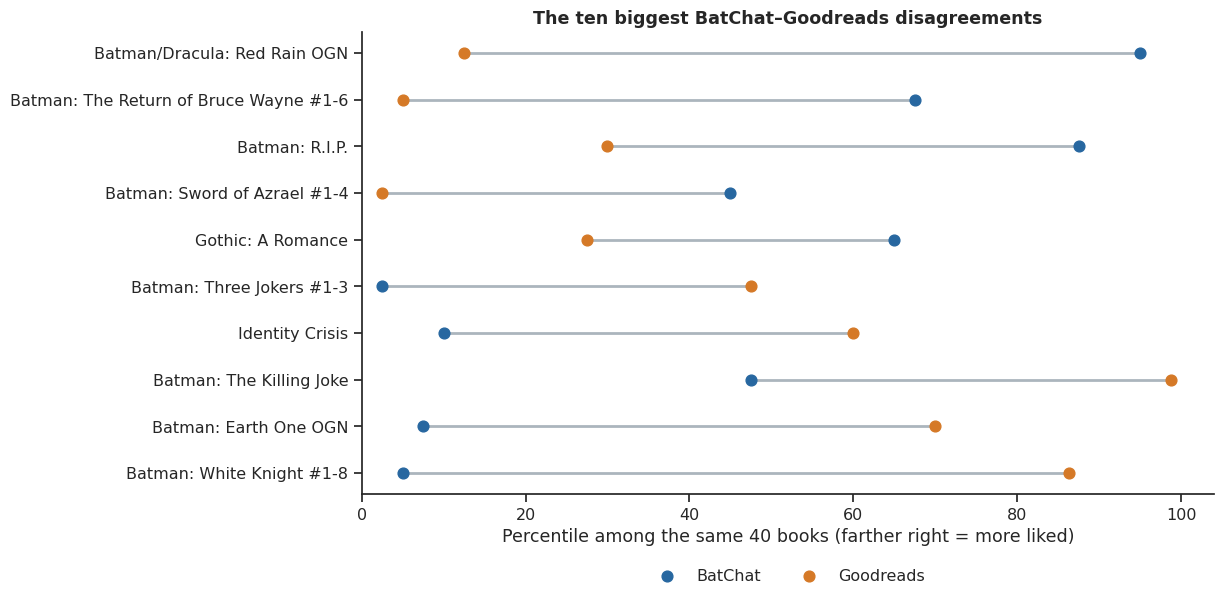

In [3]:
score, _ = audiences["Goodreads readers"]
goodreads = cohorts["Goodreads readers"].assign(
    BatChat=lambda d: d.preference.rank(pct=True) * 100,
    Goodreads=lambda d: d[score].rank(pct=True) * 100,
)
goodreads["gap"] = goodreads.BatChat - goodreads.Goodreads
shown = pd.concat([goodreads.nlargest(5, "gap"), goodreads.nsmallest(5, "gap")]).sort_values("gap")

fig, ax = plt.subplots(figsize=(11, 6))
ax.hlines(shown.title, shown.BatChat, shown.Goodreads, color="#ABB5BD", lw=2)
ax.scatter(shown.BatChat, shown.title, color=BLUE, label="BatChat", s=60, zorder=3)
ax.scatter(shown.Goodreads, shown.title, color=ORANGE, label="Goodreads", s=60, zorder=3)
ax.set(
    xlabel=f"Percentile among the same {len(goodreads)} books (farther right = more liked)",
    title="The ten biggest BatChat–Goodreads disagreements",
    xlim=(0, 104),
)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=2, frameon=False)
plt.show()

*Red Rain* sits near the top for BatChat and near the bottom for Goodreads. *White Knight* is the mirror image.

Both books reinvent Batman's world: Doug Moench and Kelley Jones turn him into a vampire, and Sean Murphy makes a supposedly reformed Joker his political rival. So "the hosts dislike unconventional Batman" doesn't explain the split. The ratings show *where* the audiences disagree, not *why*. [DC: Red Rain](https://www.dc.com/graphic-novels/batman-and-dracula-trilogy-1991/tales-of-the-multiverse-batman-vampire) · [White Knight](https://www.dc.com/blog/2017/07/07/sean-murphy-s-batman-white-knight-arrives-october-4)

*The Return of Bruce Wayne* (BatChat **#53**) is the other big BatChat-only favorite.

## 3. Is there much agreement overall?

Some. Better-rated books tend to rank higher on BatChat, but with plenty of scatter. **Each dot is one story.**

Spearman correlation summarizes how similarly two lists are ordered: **1 means the same order, 0 means no relationship.**

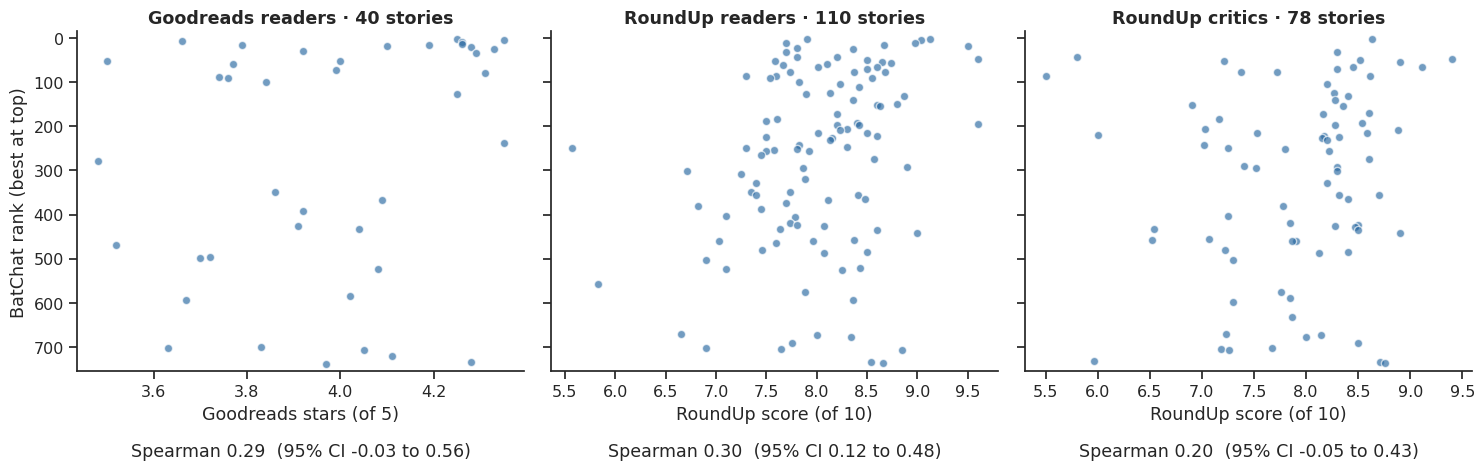

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)
for ax, (label, frame) in zip(axes, cohorts.items()):
    ratings = frame[audiences[label][0]]
    rho = spearmanr(frame.preference, ratings).statistic
    ci = spearman_interval(frame.preference, ratings)
    ax.scatter(ratings, frame["rank"], s=35, alpha=0.65, color=BLUE, edgecolors="white")
    ax.set(
        title=f"{label} · {len(frame)} stories",
        xlabel="Goodreads stars (of 5)"
        if label.startswith("Goodreads")
        else "RoundUp score (of 10)",
        ylim=(N + 15, -15),
    )
    ax.text(
        0.5,
        -0.25,
        f"Spearman {rho:.2f}  (95% CI {ci.low:.2f} to {ci.high:.2f})",
        transform=ax.transAxes,
        ha="center",
    )
axes[0].set_ylabel("BatChat rank (best at top)")
fig.tight_layout()
plt.show()

RoundUp readers agree most with BatChat (**0.30**), then Goodreads (**0.29**) and critics (**0.20**). But the intervals are wide and overlap heavily, and every panel contains different books. Let's give everyone the same list.

## 4. Readers or critics? Hold the books fixed

**69 stories** have enough reader *and* critic ratings on RoundUp. Here are the largest disagreements between the two. Both use a ten-point scale; a **positive difference means critics liked it more**.

In [5]:
paired = stories[audiences["RoundUp readers"][1] & audiences["RoundUp critics"][1]].copy()
paired["critics_minus_readers"] = paired.roundup_critic_rating - paired.roundup_user_rating
pd.concat(
    [paired.nlargest(5, "critics_minus_readers"), paired.nsmallest(5, "critics_minus_readers")]
)[
    ["title", "rank", "roundup_critic_rating", "roundup_user_rating", "critics_minus_readers"]
].set_axis(["Story", "BatChat rank", "Critics", "Readers", "Critics − readers"], axis=1).set_index(
    "Story"
).round(2)

,BatChat rank,Critics,Readers,Critics − readers
Story,,,,
Being Robin,250,7.25,5.57,1.68
Shadows,302,8.30,6.72,1.58
Batman: Black and White V.4,87,8.62,7.30,1.32
Sharkbite,356,8.70,7.40,1.30
Mindfields,380,7.78,6.82,0.95
Slay Ride,42,5.80,8.20,-2.40
The Clown at Midnight,85,5.50,7.60,-2.10
Batman and Son,458,6.52,8.38,-1.85
Blackest Knight,152,6.90,8.60,-1.70


Readers give *Slay Ride* **8.2** and critics **5.8**; BatChat ranks it **#42**. Readers also prefer *The Clown at Midnight*, Grant Morrison and John Van Fleet's illustrated prose story, **7.6 to 5.5**; BatChat puts it at **#85**. So on these two, the hosts side with the readers.

Across all 69 stories, though:

In [6]:
agreement = pd.Series(
    {
        "BatChat vs readers": spearmanr(paired.preference, paired.roundup_user_rating).statistic,
        "BatChat vs critics": spearmanr(paired.preference, paired.roundup_critic_rating).statistic,
        "Readers vs critics": spearmanr(
            paired.roundup_user_rating, paired.roundup_critic_rating
        ).statistic,
    },
    name="Spearman",
)
agreement.round(2).to_frame()

,Spearman
BatChat vs readers,0.18
BatChat vs critics,0.16
Readers vs critics,0.44


BatChat agrees about equally (and only weakly) with both: **0.18** with readers, **0.16** with critics. Readers and critics agree more with each other, at **0.44**. The hosts march to their own beat.

## 5. The surprise: publication year

Agreeing on *order* and being *generous* are different things. The chart below shows critic score minus reader score for each story, by publication decade. Above zero, critics liked the book more; below zero, readers did.

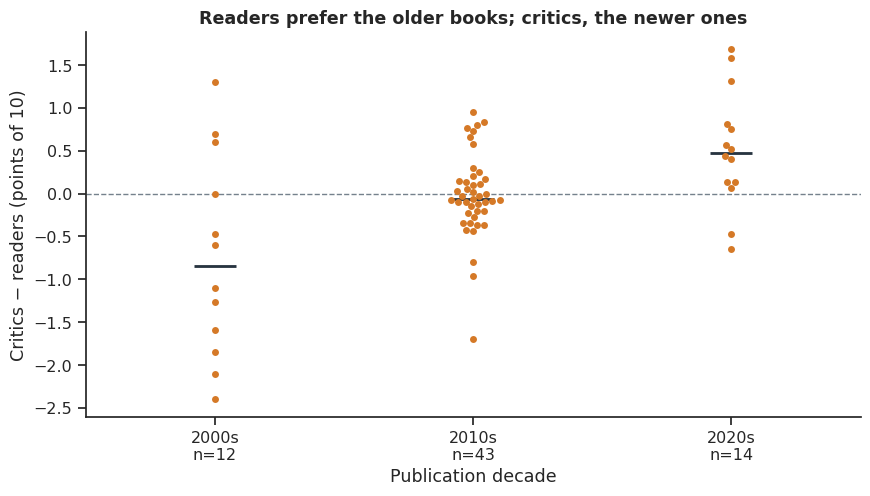

Year vs critics − readers: Spearman 0.55 (95% CI 0.32 to 0.76)
Dropping any one story leaves it between 0.53 and 0.60.


In [7]:
paired["decade"] = (paired.cover_year_start // 10 * 10).astype(int).astype(str) + "s"
order = sorted(paired.decade.unique())
fig, ax = plt.subplots(figsize=(10, 5))
sns.swarmplot(
    data=paired, x="decade", y="critics_minus_readers", order=order, color=ORANGE, size=5, ax=ax
)
sns.pointplot(
    data=paired,
    x="decade",
    y="critics_minus_readers",
    order=order,
    estimator="median",
    errorbar=None,
    linestyle="none",
    markers="_",
    markersize=30,
    color="#273440",
    ax=ax,
)
ax.axhline(0, color=GREY, lw=1, ls="--")
ax.set_xticks(range(len(order)), [f"{d}\nn={(paired.decade == d).sum()}" for d in order])
ax.set(
    xlabel="Publication decade",
    ylabel="Critics − readers (points of 10)",
    title="Readers prefer the older books; critics, the newer ones",
)
plt.show()

year_rho = spearmanr(paired.cover_year_start, paired.critics_minus_readers).statistic
ci = spearman_interval(paired.cover_year_start, paired.critics_minus_readers)
leave_one_out = [
    spearmanr(paired.drop(i).cover_year_start, paired.drop(i).critics_minus_readers).statistic
    for i in paired.index
]
print(f"Year vs critics − readers: Spearman {year_rho:.2f} (95% CI {ci.low:.2f} to {ci.high:.2f})")
print(
    f"Dropping any one story leaves it between {min(leave_one_out):.2f} and {max(leave_one_out):.2f}."
)

The median gap goes from **−0.85 points for 2000s books** to about zero in the **2010s** and **+0.48** in the **2020s**. Readers rate older comics more generously than critics do; for recent comics, it flips. The correlation with publication year is strong and doesn't hinge on any single book.

That doesn't mean critics became more generous. Different books and reviewers appear in each decade, and readers often find an older comic long after the original reviews, perhaps because it's already a classic.

## Takeaways

- The clearest disagreements are about particular books: *Red Rain* and *The Return of Bruce Wayne* do unusually well on BatChat, and *White Knight* unusually badly.
- Hold the books fixed and BatChat sides with neither readers nor critics. The hosts have their own taste.
- Readers favor older comics more than critics do, and the gap flips for recent ones.

If you've read *Red Rain* and *White Knight*, where would you put them? Is it the premise, the art, or what each story thinks Batman should be?

**Next:** [Can a computer predict BatChat's favorites?](https://www.kaggle.com/code/danofer/batchat-s-favorite-batman-stories) · [Who Gets the Good Batman Stories?](https://www.kaggle.com/code/danofer/who-gets-the-good-batman-stories) · [The dataset](https://www.kaggle.com/datasets/danofer/batchat-batman-rankings)

If you enjoyed this, an upvote helps other Batman fans find it.